#Spectral Modularity and Multi Community Detection
**Name**: RP GODHASHRI
**Roll No.**: IMS25160

1. Graph And Modularity Matrix Setup

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Zachary's Karate Club graph (34 nodes, 78 edges)
G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()

# 2. Fix node positions once so all plots keep the exact same layout
pos = nx.spring_layout(G, seed=42)

# 3. Construct the Modularity Matrix: B = A - (k * k^T) / (2m)
A = nx.to_numpy_array(G)
k = A.sum(axis=1).reshape(-1, 1)
B_full = A - (k @ k.T) / (2 * m)

print(f"Loaded Karate Club Graph: {n} nodes, {m} edges")
print(f"Modularity Matrix B shape: {B_full.shape}")

Loaded Karate Club Graph: 34 nodes, 78 edges
Modularity Matrix B shape: (34, 34)


2. Recrusive Spectral Partitioning

In [2]:
def spectral_split(nodes, B_full):
    """Performs one spectral bipartition on a subset of nodes if lambda_1 > 0."""
    if len(nodes) <= 1:
        return None

    # Extract submatrix for the current community
    idx = np.ix_(nodes, nodes)
    B_sub = B_full[idx]

    # Generalized modularity correction (ensures row sums equal 0 on subgraphs)
    B_sub = B_sub - np.diag(B_sub.sum(axis=1))

    # Compute eigenvalues and eigenvectors (sorted in ascending order)
    eigvals, eigvecs = np.linalg.eigh(B_sub)
    lambda_1 = eigvals[-1]
    u_1 = eigvecs[:, -1]

    # Stop if leading eigenvalue is nonpositive
    if lambda_1 <= 1e-10:
        return None

    # Split based on sign of leading eigenvector
    c_plus = [nodes[i] for i in range(len(nodes)) if u_1[i] > 0]
    c_minus = [nodes[i] for i in range(len(nodes)) if u_1[i] <= 0]

    if len(c_plus) == 0 or len(c_minus) == 0:
        return None

    return c_plus, c_minus

# Run recursive bisection and save community state after every split
communities = [list(G.nodes())]
history = [[list(c) for c in communities]]

while True:
    split_occurred = False
    for idx_comm, comm in enumerate(communities):
        result = spectral_split(comm, B_full)
        if result is not None:
            c_plus, c_minus = result
            new_partition = communities[:idx_comm] + [c_plus, c_minus] + communities[idx_comm + 1:]
            communities = new_partition
            history.append([list(c) for c in communities])
            split_occurred = True
            break
    if not split_occurred:
        break

print(f"Total splits performed: {len(history) - 1}")
for i, comm in enumerate(communities):
    print(f"Community {i+1}: {sorted(comm)}")

Total splits performed: 12
Community 1: [20, 32]
Community 2: [28, 31]
Community 3: [23, 27]
Community 4: [26, 29]
Community 5: [9, 15, 18, 22, 33]
Community 6: [14]
Community 7: [8, 30]
Community 8: [2, 7]
Community 9: [1, 3, 13]
Community 10: [24, 25]
Community 11: [12]
Community 12: [0, 11, 17, 19, 21]
Community 13: [4, 5, 6, 10, 16]


3. Visualize Community Splits

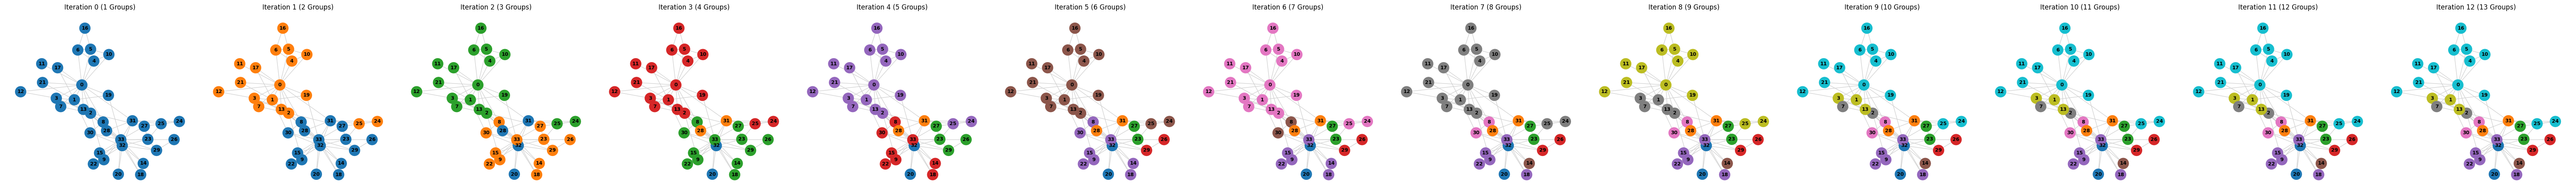

In [3]:
cmap = plt.get_cmap('tab10')
fig, axes = plt.subplots(1, len(history), figsize=(5 * len(history), 5))
if len(history) == 1:
    axes = [axes]

for step, partition in enumerate(history):
    ax = axes[step]
    node_colors = {}
    for comm_id, comm_nodes in enumerate(partition):
        for node in comm_nodes:
            node_colors[node] = cmap(comm_id)

    colors = [node_colors[node] for node in G.nodes()]
    nx.draw_networkx(
        G, pos=pos, ax=ax, node_color=colors,
        with_labels=True, node_size=380, font_size=9, font_weight='bold',
        edge_color='lightgray'
    )
    ax.set_title(f"Iteration {step} ({len(partition)} Groups)")
    ax.axis('off')

plt.tight_layout()
plt.show()

4. Compute Metrics across Splits

In [4]:
metrics_history = {
    'degree': {},
    'betweenness': {},
    'closeness': {},
    'clustering': {}
}

for step, partition in enumerate(history):
    # Keep only edges inside the same community to observe structural evolution
    G_step = nx.Graph()
    G_step.add_nodes_from(G.nodes())

    node_to_comm = {node: cid for cid, cnodes in enumerate(partition) for node in cnodes}
    for u, v in G.edges():
        if node_to_comm[u] == node_to_comm[v]:
            G_step.add_edge(u, v)

    metrics_history['degree'][step] = nx.degree_centrality(G_step)
    metrics_history['betweenness'][step] = nx.betweenness_centrality(G_step)
    metrics_history['closeness'][step] = nx.closeness_centrality(G_step)
    metrics_history['clustering'][step] = nx.clustering(G_step)

print("Computed all 4 metrics across", len(history), "iterations.")

Computed all 4 metrics across 13 iterations.


Plot Metric Evolution

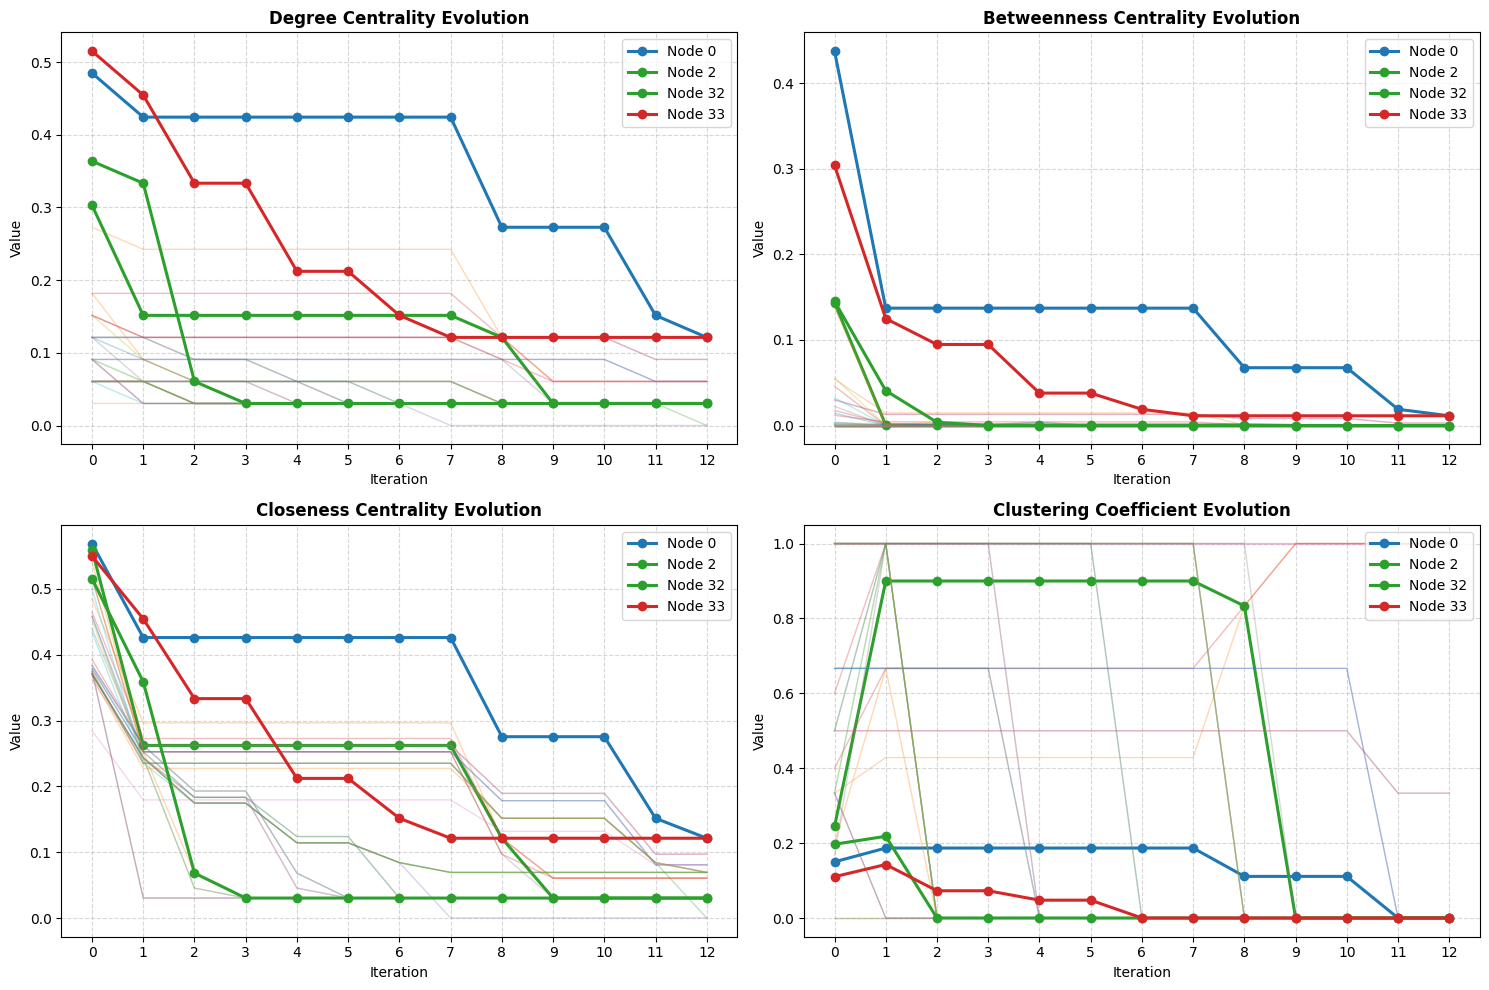

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
titles = {
    'degree': 'Degree Centrality Evolution',
    'betweenness': 'Betweenness Centrality Evolution',
    'closeness': 'Closeness Centrality Evolution',
    'clustering': 'Clustering Coefficient Evolution'
}
iterations = list(range(len(history)))

for ax, (key, title) in zip(axes.flat, titles.items()):
    for node in G.nodes():
        vals = [metrics_history[key][step][node] for step in iterations]
        if node in [0, 33, 2, 32]:  # Highlight key leaders & bridge nodes
            ax.plot(iterations, vals, marker='o', linewidth=2.2, label=f"Node {node}")
        else:
            ax.plot(iterations, vals, alpha=0.3, linewidth=1)

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Value")
    ax.set_xticks(iterations)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Discussion

Across the recursive split Node 0(Instructor) and Node 33(The club President) consistently remain central across splits. This is because both the nodes are at the dense core of their factions.

How community structure influence these metrics?

- Betweenness Centrality: At Iteration 0, boundary nodes have high betweenness as they connect the main two halves of the graph. After the 1st iteration, the bridge path disappears and betweenness drops sharply.

- Closeness Centrality: This drops steadily for all nodes as the partitions continues as cross community path disappears even though the core nodes retain highest relative closeness.

- Clustering Coefficient: This generally stays same or increase slightly after each iteration. Removing cross bridge edges removes open path while still leaving dense clusters.